### **TRABAJO CLASE N° 6 - APRENDIZAJE AUTOMÁTICO**

## Descripción del problema

**Contexto.** El abandono en la educación superior afecta a los estudiantes, a sus familias y a las instituciones. Detectar a tiempo qué estudiantes están en riesgo permite diseñar acciones de apoyo antes de que abandonen.

**Dataset.** *Predict Students' Dropout and Academic Success* (UCI Machine Learning Repository, id 697; Kaggle). Reúne datos de estudiantes de distintas carreras de grado de una institución de educación superior, provenientes de varias bases de datos. Contiene:

- **4.424 estudiantes** y **36 variables predictoras**, sin valores nulos ni filas duplicadas.
- Información **conocida al momento de la inscripción**: datos demográficos, forma de ingreso, carrera, estudios previos, educación y ocupación de los padres, y situación económica (beca, deuda, cuotas al día).
- Información del **rendimiento académico** al final del 1.er y del 2.º semestre (materias inscriptas, evaluadas y aprobadas, y notas).
- Indicadores del contexto económico del país: desempleo, inflación y PIB.
- Tipos de variables: 10 categóricas (codificadas como números), 8 binarias y 18 numéricas.

**Variable objetivo (`target`).** Situación del estudiante, con tres clases: `Graduate` (se graduó, 49,9 %), `Dropout` (abandonó, 32,1 %) y `Enrolled` (sigue cursando, 17,9 %). Es un problema de **clasificación multinomial** con desbalance moderado.

**Fuente:** Realinho, V., Machado, J., Baptista, L. y Martins, M. V. (2022). *Predicting Student Dropout and Academic Success*. Data, MDPI. Dataset en https://archive.ics.uci.edu/dataset/697

## Qué se busca responder

1. ¿Se puede predecir si un estudiante abandona, sigue cursando o se gradúa a partir de sus datos de ingreso y de su rendimiento en el primer año?
2. ¿Hay relación entre la **situación económica** (beca, deuda, cuotas atrasadas) y el resultado del estudiante?
3. ¿Qué modelo resuelve mejor el problema: **regresión logística** o **árbol de decisión**? Se comparan con las mismas métricas sobre datos de prueba.
4. ¿Qué variables pesan más en la decisión de cada modelo?

##**PASO 1 : Importar y cargar**

In [83]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, accuracy_score, f1_score)

df = pd.read_csv("https://raw.githubusercontent.com/gabrielasbacchiani/aprendizaje_automatico/refs/heads/main/CLASE6_AA/DATASETS/students_dropout_academic_success.csv")
df.shape, df.isna().sum().sum(), df.duplicated().sum()


((4424, 37), np.int64(0), np.int64(0))

**Paso 1.1 Verificar las primeras 5 filas**

In [84]:
df.head()

,Marital Status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


#**PASO 2: Explorar**


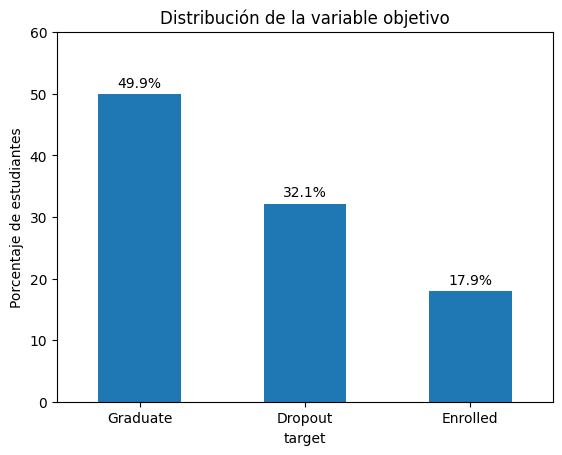

In [85]:
proporciones = df["target"].value_counts(normalize=True) * 100

ax = proporciones.plot(kind="bar", color="#1f77b4")
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
ax.set_title("Distribución de la variable objetivo")
ax.set_ylabel("Porcentaje de estudiantes")
ax.set_ylim(0, 60)
plt.xticks(rotation=0)
plt.show()

Graduate es 49,9 %, Dropout 32,1 % y Enrolled 17,9 %. Podemos observar que hay desbalance moderado.

**Paso 2.1 Preparar una copia con nombres en español**

In [86]:
df_eco = df.rename(columns={"Scholarship holder": "Becado",
                            "Debtor": "Deudor",
                            "Tuition fees up to date": "Cuotas al día"})

for col in ["Becado", "Deudor", "Cuotas al día"]:
    df_eco[col] = df_eco[col].map({0: "No", 1: "Sí"})

**Paso 2.2 Tabla de porcentajes por grupo**

In [87]:
orden = ["Graduate", "Enrolled", "Dropout"]

def tabla_porcentajes(var):
    t = pd.crosstab(df_eco[var], df_eco["target"], normalize="index")[orden] * 100
    return t.round(1)

In [88]:
tabla_porcentajes("Becado")

target,Graduate,Enrolled,Dropout
Becado,,,
No,41.3,20.0,38.7
Sí,76.0,11.8,12.2


In [89]:
tabla_porcentajes("Deudor")

target,Graduate,Enrolled,Dropout
Deudor,,,
No,53.8,18.0,28.3
Sí,20.1,17.9,62.0


In [90]:
tabla_porcentajes("Cuotas al día")

target,Graduate,Enrolled,Dropout
Cuotas al día,,,
No,5.5,8.0,86.6
Sí,56.0,19.3,24.7


**Paso 2.3 Gráfico de las tres variables**

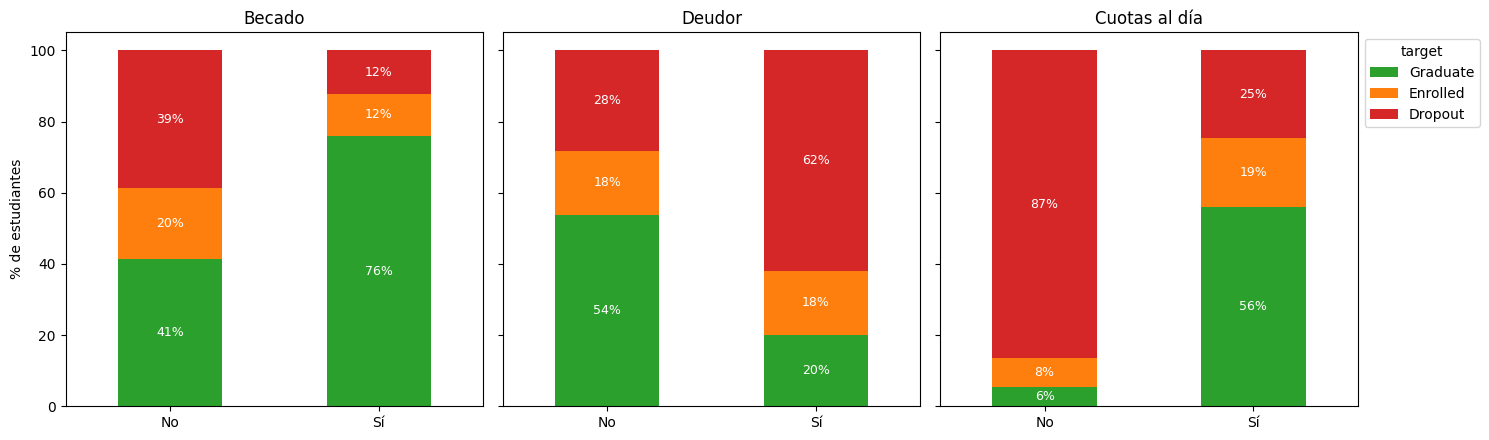

In [91]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)

for ax, var in zip(axes, ["Becado", "Deudor", "Cuotas al día"]):
    t = tabla_porcentajes(var)
    t.plot(kind="bar", stacked=True, ax=ax,
           color=["#2ca02c", "#ff7f0e", "#d62728"], legend=False)
    for c in ax.containers:
        ax.bar_label(c, fmt="%.0f%%", label_type="center", color="white", fontsize=9)
    ax.set_title(var)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=0)

axes[0].set_ylabel("% de estudiantes")
axes[2].legend(title="target", bbox_to_anchor=(1, 1), loc="upper left")
plt.tight_layout()
plt.show()

**Lectura del gráfico:** los tres gráficos muestran que la situación económica se relaciona con el resultado del estudiante.

- **Becado:** el 76,0 % de los becados se gradúa, contra el 41,3 % de los no becados. El abandono es de 12,2 % contra 38,7 %.
- **Deudor:** el 62,0 % de los deudores abandona, contra el 28,3 % de quienes no tienen deuda.
- **Cuotas al día:** es la diferencia más marcada: con cuotas atrasadas abandona el 86,6 % y solo se gradúa el 5,5 %; con cuotas al día abandona el 24,7 % y se gradúa el 56,0 %.

**Paso 2.4 Medir la asociación**

In [92]:
from scipy.stats import chi2_contingency

resultados = []
for var in ["Becado", "Deudor", "Cuotas al día"]:
    tabla = pd.crosstab(df_eco[var], df_eco["target"])
    chi2, p, gl, esperados = chi2_contingency(tabla)
    v = np.sqrt(chi2 / (tabla.values.sum() * (min(tabla.shape) - 1)))
    resultados.append({"Variable": var, "p-valor": f"{p:.1e}", "V de Cramér": round(v, 3)})

pd.DataFrame(resultados)

,Variable,p-valor,V de Cramér
0,Becado,9.6e-90,0.304
1,Deudor,4.9e-57,0.242
2,Cuotas al día,1.5e-179,0.431


**Lectura:** se aplicó la prueba chi-cuadrado, que indica si la asociación entre dos variables categóricas puede deberse al azar, y la V de Cramér, que mide su fuerza (de 0 a 1). En las tres variables el p-valor es muy inferior a 0,05, por lo que la asociación con la situación del estudiante **no es casual**. Según la V de Cramér, la más fuerte es **Cuotas al día (0,43)**, seguida por **Becado (0,30)** y **Deudor (0,24)**.

Como con 4.424 estudiantes incluso asociaciones débiles dan p-valores diminutos, para comparar la fuerza entre variables se usa la V de Cramér y no el p-valor.

**Paso 2.5 Cruzar cuotas y becas**

In [93]:
df_eco["Abandonó"] = df_eco["target"] == "Dropout"

cruce = df_eco.groupby(["Cuotas al día", "Becado"])["Abandonó"].agg(tasa="mean", n="count")
cruce["tasa"] = (cruce["tasa"] * 100).round(1)
cruce

tasa     n
Cuotas al día Becado            
No            No      89.0   482
              Sí      60.9    46
Sí            No      30.2  2843
              Sí      10.1  1053

**Lectura:** al combinar cuotas y beca, la tasa de abandono es:

| Cuotas | Becado | Abandono | Estudiantes |
|---|---|---|---|
| Atrasadas | No | 89,0 % | 482 |
| Atrasadas | Sí | 60,9 % | 46 |
| Al día | No | 30,2 % | 2.843 |
| Al día | Sí | 10,1 % | 1.053 |

La beca se asocia con menos abandono **tanto con cuotas atrasadas como al día**, pero no lo elimina cuando las cuotas están atrasadas. El grupo "cuotas atrasadas y becado" es pequeño (46 casos), por lo que ese 60,9 % debe tomarse con cautela.

## **Conclusiones del análisis exploratorio**

- Los becados se gradúan en mayor proporción (76,0 %) que los no becados (41,3 %). V de Cramér = 0,30.
- Las cuotas atrasadas son la variable más asociada al abandono: 86,6 % de abandono contra 24,7 % con cuotas al día (V = 0,43).
- La beca reduce el abandono tanto con cuotas atrasadas (89,0 % → 60,9 %) como al día (30,2 % → 10,1 %), aunque el grupo con beca y cuotas atrasadas es chico (n = 46).
- Estas son asociaciones, no causas: las cuotas atrasadas podrían ser consecuencia del abandono y no solo una causa.

# **PASO 3: Separar X e y y clasificar las columnas**

Se separa la variable objetivo (`y = target`) de las 36 variables predictoras (`X`).

Aunque en el archivo todas las columnas son numéricas, **no todas representan cantidades**. Por ejemplo, `Course = 9500` no significa "más" que `Course = 9000`: es solo el código de una carrera. Por eso las variables se agrupan según su significado real, y cada grupo recibe un tratamiento distinto:

| Grupo | Cantidad | Variables | Tratamiento |
|---|---|---|---|
| **Categóricas** | 10 | Estado civil, modalidad y orden de postulación, carrera, formación previa, nacionalidad, y nivel educativo y ocupación de ambos padres | One-Hot Encoding (una columna 0/1 por categoría) |
| **Binarias** | 8 | Turno diurno/nocturno, desplazado, necesidades especiales, deudor, cuotas al día, género, becado, internacional | Sin cambios (ya son 0/1) |
| **Numéricas** | 18 | Nota de formación previa, nota de admisión, edad al ingresar, 6 variables de rendimiento por semestre (12 en total) y 3 indicadores económicos (desempleo, inflación y PIB) | Se escalan (solo en la regresión logística) |

Esta separación es clave para el preprocesamiento del Paso 5: si los códigos se trataran como números, los modelos creerían que existe un orden o una distancia entre carreras u ocupaciones que en realidad no existe.

In [94]:
X = df.drop(columns="target")
y = df["target"]

categoricas = ["Marital Status", "Application mode", "Application order", "Course",
               "Previous qualification", "Nacionality", "Mother's qualification",
               "Father's qualification", "Mother's occupation", "Father's occupation"]

binarias = ["Daytime/evening attendance", "Displaced", "Educational special needs",
            "Debtor", "Tuition fees up to date", "Gender", "Scholarship holder",
            "International"]

numericas = [c for c in X.columns if c not in categoricas + binarias]
print(len(categoricas), len(binarias), len(numericas))   # 10, 8, 18

10 8 18


In [95]:
print("Categóricas:", categoricas)
print("\nBinarias:", binarias)
print("\nNuméricas:", numericas)

Categóricas: ['Marital Status', 'Application mode', 'Application order', 'Course', 'Previous qualification', 'Nacionality', "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation"]

Binarias: ['Daytime/evening attendance', 'Displaced', 'Educational special needs', 'Debtor', 'Tuition fees up to date', 'Gender', 'Scholarship holder', 'International']

Numéricas: ['Previous qualification (grade)', 'Admission grade', 'Age at enrollment', 'Curricular units 1st sem (credited)', 'Curricular units 1st sem (enrolled)', 'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)', 'Curricular units 1st sem (without evaluations)', 'Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)', 'Curricular units 2nd sem (without evaluations)', 'Unemployment rate', 'Inflation

#**PASO 4 Dividir en entrenamiento y prueba**

In [96]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

Se separan los datos en dos conjuntos:

- **Entrenamiento (80 %)**: los datos con los que cada modelo aprende.
- **Prueba (20 %)**: datos que el modelo nunca vio, usados solo para evaluarlo.


**Paso 4.1 Verificación**

In [97]:
print("Entrenamiento:", X_train.shape, "| Prueba:", X_test.shape)
print("\nProporción de clases en entrenamiento:")
print((y_train.value_counts(normalize=True) * 100).round(1))
print("\nProporción de clases en prueba:")
print((y_test.value_counts(normalize=True) * 100).round(1))

Entrenamiento: (3539, 36) | Prueba: (885, 36)

Proporción de clases en entrenamiento:
target
Graduate    49.9
Dropout     32.1
Enrolled    17.9
Name: proportion, dtype: float64

Proporción de clases en prueba:
target
Graduate    49.9
Dropout     32.1
Enrolled    18.0
Name: proportion, dtype: float64


#**PASO 5: Preprocesamiento**

Los modelos necesitan datos numéricos y bien escalados, y cada uno tiene necesidades distintas:

- **Variables categóricas (10):** vienen como códigos numéricos (por ejemplo `Course` o `Mother's occupation`), pero no son cantidades. Se codifican con **One-Hot Encoding**, que crea una columna 0/1 por cada categoría.
- **Variables binarias (8):** ya son 0/1, pasan sin cambios.
- **Variables numéricas (18):** notas, edad, unidades curriculares y variables económicas.
  - **Regresión logística:** se **escalan** con `StandardScaler`, porque es sensible a la magnitud de las variables.
  - **Árbol de decisión:** **no se escalan**, porque solo compara umbrales y la escala no lo afecta.

In [98]:
# Regresión logística: one-hot en categóricas + escalado de numéricas
pre_lr = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), categoricas),
    ("num", StandardScaler(), numericas)
], remainder="passthrough")          # las binarias pasan sin cambios

# Árbol: one-hot, sin escalado
pre_dt = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), categoricas)
], remainder="passthrough")

**Paso 5.1. Verificar**

In [99]:
Xtr_lr = pre_lr.fit_transform(X_train)
Xte_lr = pre_lr.transform(X_test)
print("Antes:", X_train.shape, "| Después:", Xtr_lr.shape, "| Prueba:", Xte_lr.shape)

Antes: (3539, 36) | Después: (3539, 243) | Prueba: (885, 243)


#**PASO 6: Modelos base**

Se arman dos modelos con el preprocesamiento del paso 5, **sin ajustar hiperparámetros** todavía:

- **Regresión logística:** calcula la probabilidad de pertenecer a cada clase y traza fronteras lineales. Como hay tres clases, es multinomial (softmax).
- **Árbol de decisión:** hace preguntas sucesivas sobre las variables hasta llegar a una clase. Sin límites de profundidad, puede crecer hasta memorizar los datos.

Se compara la exactitud (*accuracy*) en **entrenamiento** y en **prueba**: si la diferencia es grande, hay **sobreajuste**.

In [100]:
lr = Pipeline([("pre", pre_lr), ("m", LogisticRegression(max_iter=2000))])
dt = Pipeline([("pre", pre_dt), ("m", DecisionTreeClassifier(random_state=42))])

for nombre, modelo in [("Reg. logística", lr), ("Árbol", dt)]:
    modelo.fit(X_train, y_train)
    print(nombre, "| train:", round(modelo.score(X_train, y_train), 3),
          "| test:", round(modelo.score(X_test, y_test), 3))

Reg. logística | train: 0.811 | test: 0.768
Árbol | train: 1.0 | test: 0.682


**Observaciones:** el árbol sin restricciones alcanza una accuracy de 1,0 en entrenamiento pero solo 0,68 en prueba, lo que indica sobreajuste. La regresión logística mantiene un rendimiento estable (0,81 en entrenamiento y 0,77 en prueba). En el próximo paso se ajustan los hiperparámetros del árbol (profundidad máxima y mínimo de muestras por hoja) para reducir el sobreajuste.

# **PASO 7: Ajuste de hiperparámetros con validación cruzada**

Los **hiperparámetros** son valores que se fijan antes de entrenar y controlan cómo aprende el modelo. En lugar de elegirlos a ojo, se prueban varias combinaciones con `GridSearchCV`:

- **Regresión logística:** `C` controla la regularización. Un `C` chico penaliza más los coeficientes grandes (modelo más simple); un `C` grande da más libertad al modelo.
- **Árbol de decisión:** `max_depth` limita la profundidad del árbol y `min_samples_leaf` exige un mínimo de estudiantes en cada hoja. Ambos frenan el sobreajuste.

Se usa **validación cruzada estratificada de 5 particiones**: los datos de entrenamiento se dividen en 5 partes, y cada combinación se entrena 5 veces, dejando una parte afuera para evaluar. Así la elección no depende de una sola división.

La métrica elegida es **F1 macro**, que promedia el F1 de las tres clases por igual. Es más justa que la accuracy cuando hay una clase minoritaria (*Enrolled*, 17,9 %).

La búsqueda se hace **solo con los datos de entrenamiento**; el conjunto de prueba se reserva para la evaluación final.

In [101]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

gs_lr = GridSearchCV(lr, {"m__C": [0.01, 0.1, 1, 10]},
                     cv=cv, scoring="f1_macro")
gs_dt = GridSearchCV(dt, {"m__max_depth": [3, 4, 5, 6, 8, 10],
                          "m__min_samples_leaf": [1, 5, 10, 20]},
                     cv=cv, scoring="f1_macro")

gs_lr.fit(X_train, y_train)
gs_dt.fit(X_train, y_train)

print("Reg. logística:", gs_lr.best_params_, "| F1 macro CV:", round(gs_lr.best_score_, 3))
print("Árbol:", gs_dt.best_params_, "| F1 macro CV:", round(gs_dt.best_score_, 3))

Reg. logística: {'m__C': 1} | F1 macro CV: 0.698
Árbol: {'m__max_depth': 8, 'm__min_samples_leaf': 20} | F1 macro CV: 0.675


La búsqueda probó 4 combinaciones para la logística y 24 para el árbol (6 profundidades por 4 valores de hojas), cada una con 5 particiones.


La logística queda con C = 1, que es justo el valor por defecto. Es decir, el modelo base ya estaba bien ajustado y la búsqueda no lo mejora.
El árbol pasa de crecer sin límites a una profundidad de 8 con al menos 20 estudiantes por hoja. Eso lo “poda” y reduce el sobreajuste.

**Paso 7.1 Comparación con el árbol del paso 6**

In [102]:
mejor_dt = gs_dt.best_estimator_
print("Árbol ajustado | train:", round(mejor_dt.score(X_train, y_train), 3),
      "| test:", round(mejor_dt.score(X_test, y_test), 3))

Árbol ajustado | train: 0.789 | test: 0.733


**Observaciones:** la validación cruzada eligió `C = 1` para la regresión logística (F1 macro = 0,70) y `max_depth = 8` con `min_samples_leaf = 20` para el árbol (F1 macro = 0,68). Al limitar el árbol, la diferencia entre entrenamiento y prueba bajó de unos 32 puntos a unos 6, lo que confirma que el sobreajuste se redujo.

# **PASO 8: Evaluación en el conjunto de prueba**

Ahora se evalúan los dos modelos ajustados con los **885 estudiantes de prueba**, que no se usaron ni para entrenar ni para elegir hiperparámetros. Se miran:

- **Accuracy:** porcentaje total de aciertos.
- **Precision:** de los estudiantes que el modelo asignó a una clase, cuántos realmente pertenecían a ella.
- **Recall:** de los estudiantes que realmente pertenecen a una clase, cuántos detectó el modelo.
- **F1:** promedio armónico entre precision y recall.
- **F1 macro:** promedio del F1 de las tres clases por igual. Es la métrica más justa acá, porque *Enrolled* es minoritaria.
- **Matriz de confusión:** muestra en qué clases se confunde cada modelo.


=== Regresión logística ===
Accuracy: 0.768 | F1 macro: 0.696
              precision    recall  f1-score   support

     Dropout       0.79      0.75      0.77       284
    Enrolled       0.55      0.40      0.46       159
    Graduate       0.81      0.91      0.86       442

    accuracy                           0.77       885
   macro avg       0.72      0.69      0.70       885
weighted avg       0.76      0.77      0.76       885



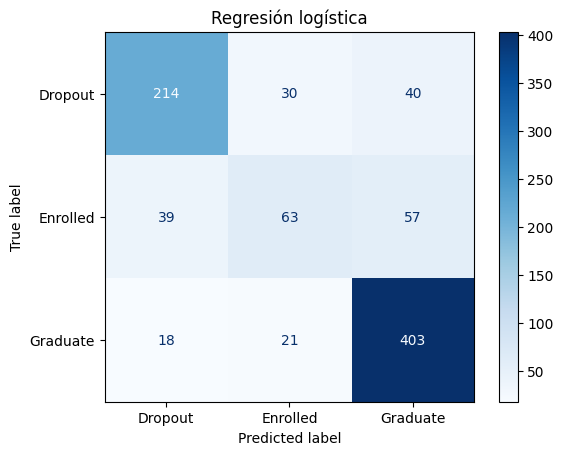


=== Árbol de decisión ===
Accuracy: 0.733 | F1 macro: 0.656
              precision    recall  f1-score   support

     Dropout       0.72      0.72      0.72       284
    Enrolled       0.48      0.36      0.41       159
    Graduate       0.81      0.88      0.84       442

    accuracy                           0.73       885
   macro avg       0.67      0.65      0.66       885
weighted avg       0.72      0.73      0.72       885



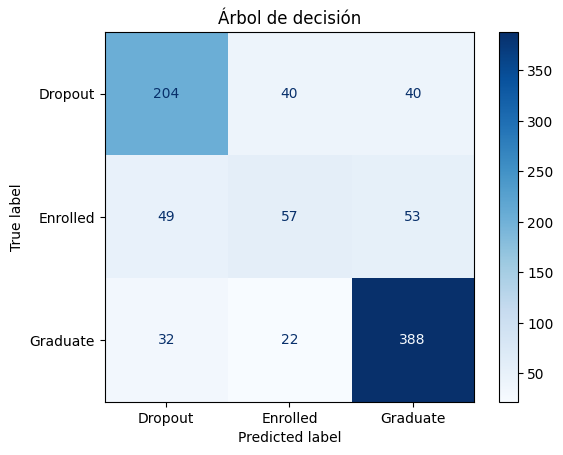

In [103]:
etiquetas = ["Dropout", "Enrolled", "Graduate"]

for nombre, g in [("Regresión logística", gs_lr), ("Árbol de decisión", gs_dt)]:
    pred = g.predict(X_test)
    print(f"\n=== {nombre} ===")
    print("Accuracy:", round(accuracy_score(y_test, pred), 3),
          "| F1 macro:", round(f1_score(y_test, pred, average="macro"), 3))
    print(classification_report(y_test, pred))
    ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=etiquetas, cmap="Blues")
    plt.title(nombre)
    plt.show()

**Observaciones:** la regresión logística supera al árbol en el conjunto de prueba (accuracy 0,77 contra 0,73; F1 macro 0,70 contra 0,66). Ambos modelos clasifican bien a los graduados (recall 0,91 y 0,88) y razonablemente a quienes abandonan (0,75 y 0,72), pero tienen dificultades con *Enrolled* (recall 0,40 y 0,36), que se confunde con las otras dos clases al ser un estado intermedio. Como mejora posible se podría probar `class_weight="balanced"` para dar más peso a la clase minoritaria.

# **PASO 9: Interpretabilidad de los modelos**

Además de medir qué tan bien predice cada modelo, interesa entender **qué variables usa** para decidir:

- **Árbol de decisión:** la *importancia de variables* indica cuánto contribuye cada una a reducir la impureza en las divisiones del árbol (suman 100 %). También se puede visualizar el árbol y leer sus reglas.
- **Regresión logística:** hay un **coeficiente por variable y por clase**. Un coeficiente positivo en la clase *Dropout* empuja la predicción hacia el abandono; uno negativo la aleja. Como las numéricas están escaladas, sus coeficientes son comparables entre sí.

**Paso 9.1 Importancia de variables del árbol**

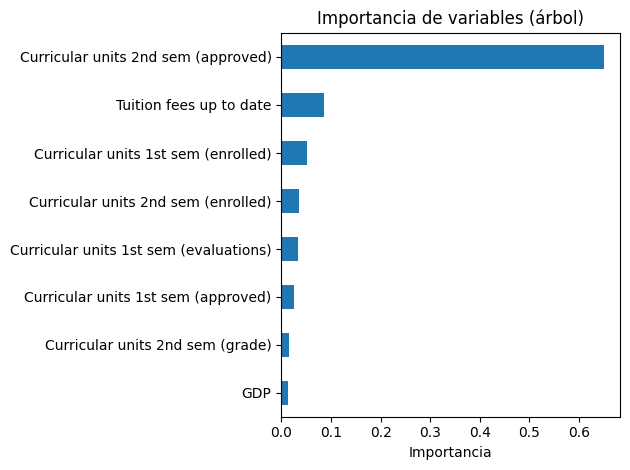

In [104]:
mejor_dt = gs_dt.best_estimator_
nombres_dt = [n.split("__", 1)[1] for n in mejor_dt["pre"].get_feature_names_out()]

imp = pd.Series(mejor_dt["m"].feature_importances_, index=nombres_dt)
imp.sort_values(ascending=False).head(8).plot(kind="barh", color="#1f77b4").invert_yaxis()
plt.xlabel("Importancia")
plt.title("Importancia de variables (árbol)")
plt.tight_layout()
plt.show()

**Paso 9.2 Visualización del árbol**

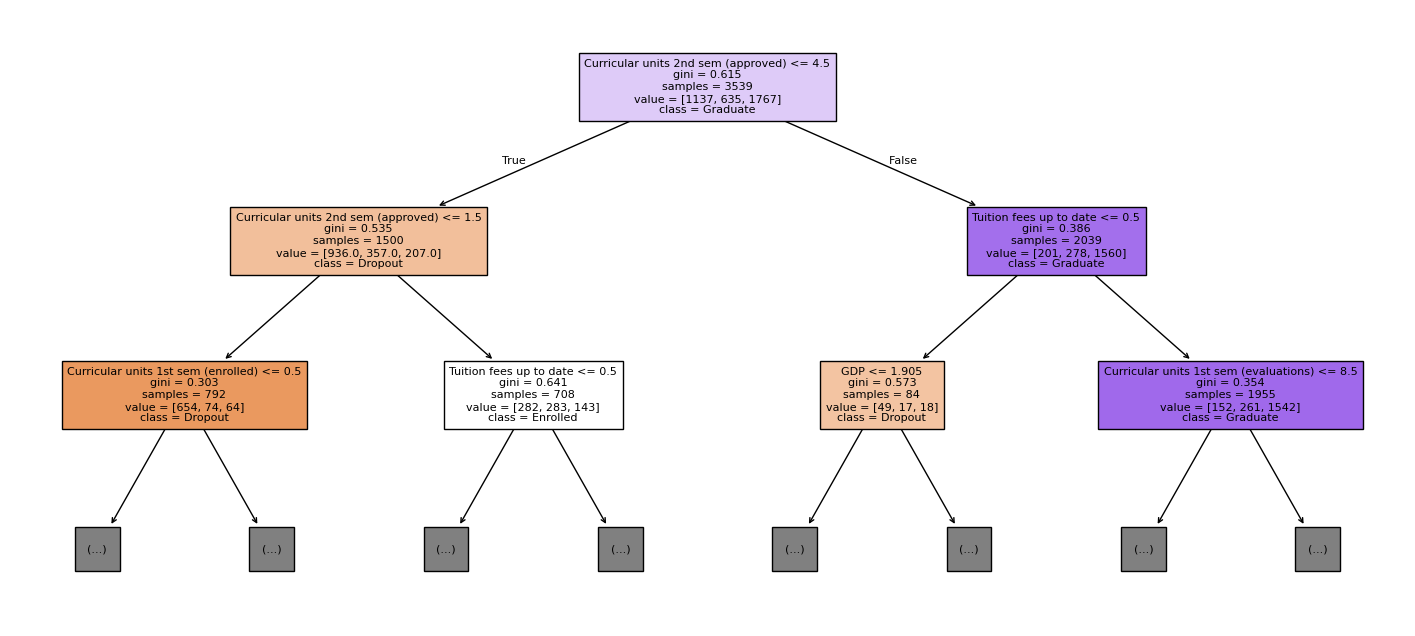

In [105]:
plt.figure(figsize=(18, 8))
plot_tree(mejor_dt["m"], max_depth=2, feature_names=nombres_dt,
          class_names=mejor_dt["m"].classes_, filled=True, fontsize=8)
plt.show()

**Paso 9.3 Coeficientes de la regresión logística**

In [106]:
mejor_lr = gs_lr.best_estimator_
nombres_lr = [n.split("__", 1)[1] for n in mejor_lr["pre"].get_feature_names_out()]

coefs = pd.DataFrame(mejor_lr["m"].coef_.T, index=nombres_lr,
                     columns=mejor_lr["m"].classes_)

print("Variables que más empujan hacia el abandono:")
print(coefs["Dropout"].sort_values().tail(8).round(2))
print("\nVariables que más alejan del abandono:")
print(coefs["Dropout"].sort_values().head(8).round(2))

Variables que más empujan hacia el abandono:
Previous qualification_4               0.66
Mother's occupation_90                 0.71
Previous qualification_2               0.74
Course_9130                            0.81
Course_9853                            0.86
Curricular units 2nd sem (enrolled)    0.86
Father's occupation_90                 1.05
Mother's occupation_0                  1.12
Name: Dropout, dtype: float64

Variables que más alejan del abandono:
Tuition fees up to date               -1.75
Curricular units 2nd sem (approved)   -1.54
Mother's occupation_191               -1.19
Curricular units 1st sem (approved)   -0.83
Application mode_15                   -0.82
Course_171                            -0.79
Mother's qualification_4              -0.72
Nacionality_25                        -0.67
Name: Dropout, dtype: float64


**Observaciones:** ambos modelos coinciden en que las variables más relevantes son el rendimiento académico (unidades curriculares aprobadas, sobre todo del 2.º semestre, que concentran el 65 % de la importancia en el árbol) y la situación de pagos (cuotas al día). En la regresión logística, estas mismas variables reducen la probabilidad de abandono (coeficientes negativos para *Dropout*). Esto es coherente con el análisis exploratorio. Como limitación, el modelo se apoya en información que solo está disponible una vez avanzada la cursada, por lo que serviría más para detectar el riesgo que para prevenirlo desde el ingreso.

**Paso 9.4 Coeficientes de las variables numéricas y binarias**

Las variables categóricas con one-hot generan muchas columnas con pocos estudiantes cada una, y sus coeficientes son inestables. Para una lectura más clara se muestran solo los coeficientes de las variables **binarias y numéricas** (26 en total), que tienen muchos estudiantes detrás y son comparables entre sí.

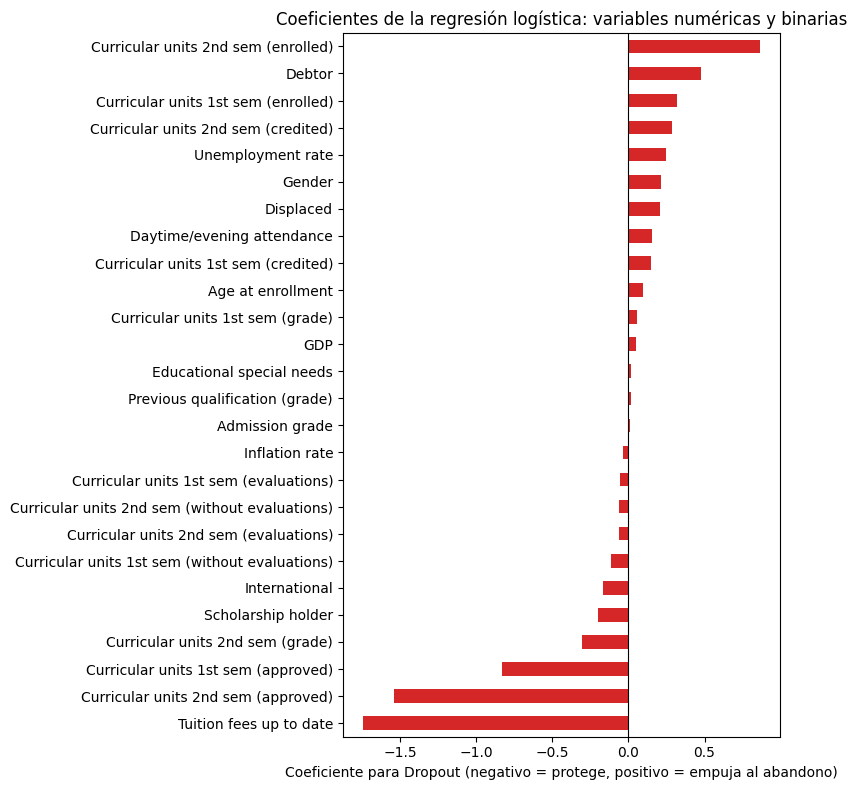

,Dropout,Enrolled,Graduate
Tuition fees up to date,-1.75,0.25,1.49
Curricular units 2nd sem (approved),-1.54,-0.38,1.92
Curricular units 1st sem (approved),-0.83,-0.42,1.26
Curricular units 2nd sem (grade),-0.30,0.03,0.27
Scholarship holder,-0.20,-0.29,0.49
International,-0.17,0.18,-0.01
Curricular units 1st sem (without evaluations),-0.11,0.05,0.07
Curricular units 2nd sem (evaluations),-0.06,0.26,-0.20
Curricular units 2nd sem (without evaluations),-0.06,-0.06,0.12
Curricular units 1st sem (evaluations),-0.06,0.20,-0.14


In [107]:
coefs_num = coefs.loc[binarias + numericas]                       # solo binarias y numéricas
coefs_num = coefs_num.sort_values("Dropout")

coefs_num["Dropout"].plot(kind="barh", color="#d62728", figsize=(8, 8))
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Coeficiente para Dropout (negativo = protege, positivo = empuja al abandono)")
plt.title("Coeficientes de la regresión logística: variables numéricas y binarias")
plt.tight_layout()
plt.show()

coefs_num.round(2)

**Observaciones:** entre las variables binarias y numéricas, los coeficientes más fuertes para *Dropout* son tener las cuotas al día (−1,75) y las unidades aprobadas del 2.º y del 1.er semestre (−1,54 y −0,83), todos factores protectores. Tener deuda (+0,48) y estar inscripto en más unidades de las que se aprueban (+0,86) empujan hacia el abandono. La beca tiene un coeficiente pequeño (−0,20) pese a su fuerte asociación en el análisis exploratorio, porque su efecto queda en gran parte explicado por el rendimiento académico y la situación de pagos.

# **PASO 10: Comparación final de los modelos**

Se resumen en una sola tabla las métricas de ambos modelos ajustados. Todas las métricas de prueba se calculan sobre los 885 estudiantes que no se usaron para entrenar ni para elegir hiperparámetros.

In [108]:
etiquetas = ["Dropout", "Enrolled", "Graduate"]
filas = {}

for nombre, g in [("Regresión logística", gs_lr), ("Árbol de decisión", gs_dt)]:
    pred = g.predict(X_test)
    rep = classification_report(y_test, pred, output_dict=True)
    filas[nombre] = {
        "Accuracy train": accuracy_score(y_train, g.predict(X_train)),
        "Accuracy test": accuracy_score(y_test, pred),
        "F1 macro test": f1_score(y_test, pred, average="macro"),
        "Recall Dropout": rep["Dropout"]["recall"],
        "Recall Enrolled": rep["Enrolled"]["recall"],
        "Recall Graduate": rep["Graduate"]["recall"],
    }

resumen = pd.DataFrame(filas).T.round(3)
resumen

,Accuracy train,Accuracy test,F1 macro test,Recall Dropout,Recall Enrolled,Recall Graduate
Regresión logística,0.811,0.768,0.696,0.754,0.396,0.912
Árbol de decisión,0.789,0.733,0.656,0.718,0.358,0.878


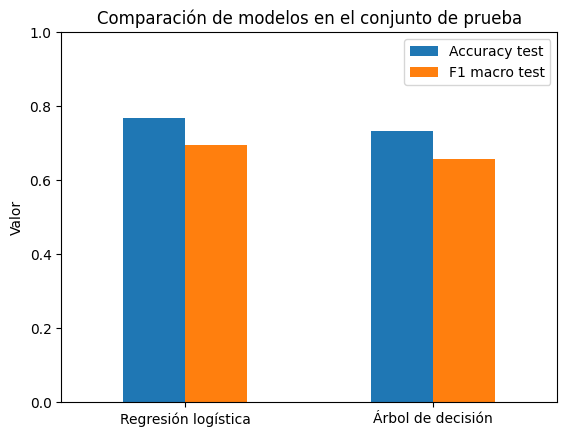

In [109]:
resumen[["Accuracy test", "F1 macro test"]].plot(kind="bar", rot=0, color=["#1f77b4", "#ff7f0e"])
plt.ylim(0, 1)
plt.ylabel("Valor")
plt.title("Comparación de modelos en el conjunto de prueba")
plt.show()

## Conclusión

**Modelo elegido: regresión logística.** Rinde mejor que el árbol de decisión en el conjunto de prueba (accuracy 0,77 contra 0,73 y F1 macro 0,70 contra 0,66) y mejora el recall en las tres clases.
Esto es así porque:
- Generaliza mejor: la diferencia entre entrenamiento y prueba es de unos 4 puntos, contra unos 6 del árbol ya podado (y unos 32 del árbol sin límites del paso 6).
- Con muchas variables categóricas codificadas con one-hot (243 columnas en total), un modelo lineal regularizado resulta más estable que un árbol, que tiende a sobreajustar.

**Ventajas del árbol:** no necesita escalar los datos y sus reglas se leen fácilmente. En este problema, además, confirmó qué variables pesan más: unidades aprobadas del 2.º semestre (65 % de la importancia) y cuotas al día.

**Limitaciones:**
- Ambos modelos tienen dificultades con *Enrolled* (recall 0,40 y 0,36), un estado intermedio sin un perfil propio claro.
- Las variables más importantes (rendimiento del 2.º semestre) solo se conocen con la cursada avanzada, por lo que los modelos sirven más para detectar el riesgo que para prevenirlo desde el ingreso.

**Posibles mejoras:** usar `class_weight="balanced"` para dar más peso a la clase minoritaria, probar un modelo sin las variables del 2.º semestre (predicción temprana) o probar modelos más potentes.